# 주택 가격 예측하기

메인퀘스트에 오신 것을 환영합니다!

이번 퀘스트의 목표는 여러 특성들을 종합적으로 고려하여 가장 주택 가격을 잘 예측하는 회귀모델을 만드는 것입니다.

- 예측할 값(y): SalePrice
- 평가지표: RMSE

예시 형식:
~~~
Id,SalePrice
1461,169000.1
1462,187724.1233
1463,175221
etc.
~~~

### 데이터 확인 및 불러오기

In [16]:
import numpy as np
import pandas as pd
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

In [17]:
train_df = pd.read_csv('./train.csv')
test_df = pd.read_csv('./test.csv')

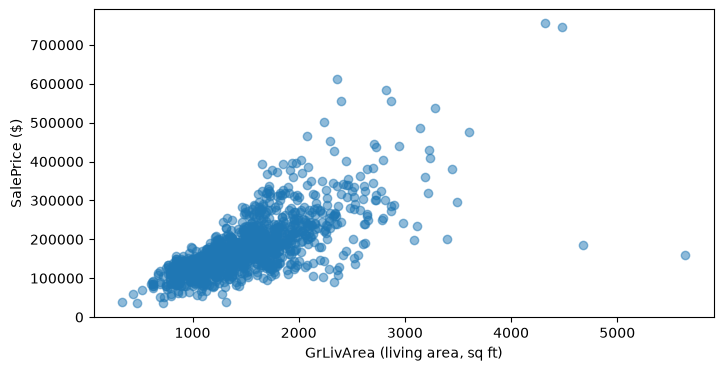

In [18]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(train_df["GrLivArea"], train_df["SalePrice"], alpha=0.5)
ax.set_xlabel("GrLivArea (living area, sq ft)")
ax.set_ylabel("SalePrice ($)")
plt.show()

In [19]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1168 entries, 0 to 1167
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1168 non-null   int64  
 1   MSSubClass     1168 non-null   int64  
 2   MSZoning       1168 non-null   str    
 3   LotFrontage    950 non-null    float64
 4   LotArea        1168 non-null   int64  
 5   Street         1168 non-null   str    
 6   Alley          70 non-null     str    
 7   LotShape       1168 non-null   str    
 8   LandContour    1168 non-null   str    
 9   Utilities      1168 non-null   str    
 10  LotConfig      1168 non-null   str    
 11  LandSlope      1168 non-null   str    
 12  Neighborhood   1168 non-null   str    
 13  Condition1     1168 non-null   str    
 14  Condition2     1168 non-null   str    
 15  BldgType       1168 non-null   str    
 16  HouseStyle     1168 non-null   str    
 17  OverallQual    1168 non-null   int64  
 18  OverallCond    1168

특성이 너무 많습니다! 어떻게 하면 좋을까요?

참고로 각각의 특성은 다음을 나타냅니다.

| 변수명               | 설명 (한국어)                         |
| ----------------- | -------------------------------- |
| **SalePrice**     | 주택의 판매 가격(달러). 예측해야 하는 타겟 변수     |
| **MSSubClass**    | 건물 등급(건물 종류 분류)                  |
| **MSZoning**      | 토지 용도 구분(일반적인 구역 분류)             |
| **LotFrontage**   | 도로에 접한 토지 길이 (피트 단위)             |
| **LotArea**       | 토지 면적 (평방 피트)                    |
| **Street**        | 도로 접근 방식                         |
| **Alley**         | 골목(후면 도로) 접근 방식                  |
| **LotShape**      | 토지의 전반적인 모양                      |
| **LandContour**   | 토지의 평탄도                          |
| **Utilities**     | 사용 가능한 공공시설(전기, 수도 등)            |
| **LotConfig**     | 토지 배치 형태                         |
| **LandSlope**     | 토지의 경사도                          |
| **Neighborhood**  | Ames 시 내의 물리적 위치(주변 지역)          |
| **Condition1**    | 주요 도로·철도에 대한 근접도                 |
| **Condition2**    | 두 번째 주요 도로·철도에 대한 근접도            |
| **BldgType**      | 주거 건물 유형 (단독, 다세대 등)             |
| **HouseStyle**    | 주택의 건축 양식                        |
| **OverallQual**   | 자재 및 마감 품질 종합 평가                 |
| **OverallCond**   | 주택의 전반적인 상태 평가                   |
| **YearBuilt**     | 최초 건축 연도                         |
| **YearRemodAdd**  | 리모델링/개조 연도                       |
| **RoofStyle**     | 지붕 스타일                           |
| **RoofMatl**      | 지붕 재료                            |
| **Exterior1st**   | 외장 마감재(주 재료)                     |
| **Exterior2nd**   | 외장 마감재(보조 재료, 2번째)               |
| **MasVnrType**    | 석조 베니어 타입                        |
| **MasVnrArea**    | 석조 베니어 면적 (평방 피트)                |
| **ExterQual**     | 외장재 품질 평가                        |
| **ExterCond**     | 외장재 상태 평가                        |
| **Foundation**    | 기초(Foundation) 유형                |
| **BsmtQual**      | 지하실 높이 평가                        |
| **BsmtCond**      | 지하실 상태 평가                        |
| **BsmtExposure**  | 지하실 외부 노출 여부(출입구/창문 등)           |
| **BsmtFinType1**  | 주요 지하실 마감 구역 유형                  |
| **BsmtFinSF1**    | 주요 지하실 마감 면적 (평방 피트)             |
| **BsmtFinType2**  | 보조 지하실 마감 구역 유형                  |
| **BsmtFinSF2**    | 보조 지하실 마감 면적 (평방 피트)             |
| **BsmtUnfSF**     | 미완성 지하실 면적 (평방 피트)               |
| **TotalBsmtSF**   | 지하실 전체 면적 (평방 피트)                |
| **Heating**       | 난방 시스템 종류                        |
| **HeatingQC**     | 난방 품질 및 상태                       |
| **CentralAir**    | 중앙 에어컨 설치 여부                     |
| **Electrical**    | 전기 시스템 종류                        |
| **1stFlrSF**      | 1층 면적 (평방 피트)                    |
| **2ndFlrSF**      | 2층 면적 (평방 피트)                    |
| **LowQualFinSF**  | 저품질 마감 공간 면적 (전체 층 합산)           |
| **GrLivArea**     | 지상(Above grade) 생활 공간 면적 (평방 피트) |
| **BsmtFullBath**  | 지하실 완비 욕실 수                      |
| **BsmtHalfBath**  | 지하실 반 욕실 수                       |
| **FullBath**      | 지상 완비 욕실 수                       |
| **HalfBath**      | 지상 반 욕실 수                        |
| **Bedroom**       | 지하실 제외 침실 수                      |
| **Kitchen**       | 주방 수                             |
| **KitchenQual**   | 주방 품질                            |
| **TotRmsAbvGrd**  | 지상 전체 방 개수 (욕실 제외)               |
| **Functional**    | 주택 기능성 평가                        |
| **Fireplaces**    | 벽난로 개수                           |
| **FireplaceQu**   | 벽난로 품질                           |
| **GarageType**    | 차고 위치(유형)                        |
| **GarageYrBlt**   | 차고 건축 연도                         |
| **GarageFinish**  | 차고 내부 마감 상태                      |
| **GarageCars**    | 차고 크기 (주차 가능 차량 수)               |
| **GarageArea**    | 차고 면적 (평방 피트)                    |
| **GarageQual**    | 차고 품질                            |
| **GarageCond**    | 차고 상태                            |
| **PavedDrive**    | 포장 진입로 여부                        |
| **WoodDeckSF**    | 목재 데크 면적 (평방 피트)                 |
| **OpenPorchSF**   | 오픈 현관 면적 (평방 피트)                 |
| **EnclosedPorch** | 밀폐된 현관 면적 (평방 피트)                |
| **3SsnPorch**     | 3계절용 현관 면적 (평방 피트)               |
| **ScreenPorch**   | 스크린 현관 면적 (평방 피트)                |
| **PoolArea**      | 수영장 면적 (평방 피트)                   |
| **PoolQC**        | 수영장 품질                           |
| **Fence**         | 울타리 품질                           |
| **MiscFeature**   | 기타 특수 기능                         |
| **MiscVal**       | 기타 기능의 금전적 가치                    |
| **MoSold**        | 판매 월                             |
| **YrSold**        | 판매 연도                            |
| **SaleType**      | 판매 유형                            |
| **SaleCondition** | 판매 조건                            |


In [20]:
train_df.head(3)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,968,20,RL,NaN,7390,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2008,WD,Normal,135000
1,739,90,RL,60.0,10800,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,3,2009,WD,Alloca,179000
2,696,20,RL,54.0,13811,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2006,WD,Normal,176000


In [21]:
print(train_df.isnull().sum())

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      218
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64


In [22]:
# 면적(SF, Area)이 들어간 열
print([c for c in train_df.columns if "SF" in c or "Area" in c])

# 연도(Yr, Year)가 들어간 열
print([c for c in train_df.columns if "Yr" in c or "Year" in c])

# 욕실(Bath)이 들어간 열
print([c for c in train_df.columns if "Bath" in c])

['LotArea', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'PoolArea']
['YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'YrSold']
['BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath']


### 전처리

전처리에서 고민해야 할 것은 많습니다.

1. 결측치
2. 이상치

결측치는 처리하지 않으면 학습 자체가 불가할 수 있기 때문에, 최소한의 전처리로 결측치를 처리하겠습니다.

여러분들이라면 어떻게 결측치를 처리하면 좋을지 고민해보세요!

In [23]:
# ★ 1. "없음"이라는 뜻인 빈 값 → "None"
none_cols = ["Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
             "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond",
             "PoolQC", "Fence", "MiscFeature", "MasVnrType"]
train_df[none_cols] = train_df[none_cols].fillna("None")

# ★ 2. 차고 연도 빈 칸 → 그 집의 건축 연도
train_df["GarageYrBlt"] = train_df["GarageYrBlt"].fillna(train_df["YearBuilt"])

# ★ 3. 학습용 기준값을 따로 저장해 두기 (테스트에서 그대로 쓰려고)
train_median = train_df.median(numeric_only=True)
train_mode = {col: train_df[col].mode()[0] for col in train_df.select_dtypes(include=["object", "str"])}

# 수치형 → 중앙값
train_df = train_df.fillna(train_median)
# 범주형 → 최빈값
for col in train_mode:
    train_df[col] = train_df[col].fillna(train_mode[col])

# ★ 5. 새 피처 만들기
train_df["TotalSF"] = train_df["TotalBsmtSF"] + train_df["1stFlrSF"] + train_df["2ndFlrSF"]
train_df["HouseAge"] = train_df["YrSold"] - train_df["YearBuilt"]
train_df["RemodAge"] = train_df["YrSold"] - train_df["YearRemodAdd"]
train_df["TotalBath"] = (train_df["FullBath"] + train_df["BsmtFullBath"]
                         + 0.5 * (train_df["HalfBath"] + train_df["BsmtHalfBath"]))
train_df["QualxSF"] = train_df["TotalSF"] * train_df["OverallQual"]
train_df["Qual2"] = train_df["OverallQual"] * train_df["OverallQual"]

# ★ 6. 비싼 집 피처: 고급 동네, 신축
rich_nb = ["NridgHt", "NoRidge", "StoneBr"]
train_df["RichNb"] = train_df["Neighborhood"].isin(rich_nb).astype(int)
train_df["RichxSF"] = train_df["RichNb"] * train_df["TotalSF"]
train_df["IsNew"] = (train_df["SaleType"] == "New").astype(int)
train_df["NewxSF"] = train_df["IsNew"] * train_df["TotalSF"]

# ★ 8. 면적 로그 + 품질 점수
train_df["LogSF"] = np.log1p(train_df["TotalSF"])        # 총면적 로그: 넓을수록 1평의 값어치가 둔해지게
train_df["LogLot"] = np.log1p(train_df["LotArea"])       # 땅 면적 로그
q_map = {"Ex": 5, "Gd": 4, "TA": 3, "Fa": 2, "Po": 1, "None": 0}
q_cols = ["ExterQual", "KitchenQual", "BsmtQual", "HeatingQC", "FireplaceQu", "GarageQual"]
train_df["QScore"] = sum(train_df[c].map(q_map).fillna(0) for c in q_cols)   # 여섯 곳 품질 점수의 합
train_df["QScorexSF"] = train_df["QScore"] * train_df["TotalSF"]

# ★ 12. 이름표 숫자를 범주(글자)로: 크기가 아니라 종류를 뜻하는 열
train_df["MSSubClass"] = train_df["MSSubClass"].astype(str)        # 주택 유형 (Chapter 2에서 배운 이름표)
train_df["CondCat"] = train_df["OverallCond"].astype(str)          # 전체 상태 등급을 범주로도 한 번 더


# 범주형 원 핫 인코딩  (★ 4. drop_first 빼기)
train_df = pd.get_dummies(train_df)

### 모델 설정 및 학습

In [24]:
from sklearn.model_selection import train_test_split

X = train_df.drop(["SalePrice", "Id"], axis=1)   # ★ 9. 번호표(Id)도 빼기
y = train_df["SalePrice"]

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)   # (원래 코드)

# ★ 이상치 빼기: 면적이 아주 넓은데(4500 초과) 가격이 싼(30만 미만) 집 → 학습용에서만
outlier = (X_train["GrLivArea"] > 4500) & (y_train < 300000)
print("뺀 집 수:", outlier.sum())

X_train = X_train[~outlier]
y_train = y_train[~outlier]

뺀 집 수: 2


In [25]:
# ★ 13. K-Fold 교차 검증 (5번 나눠 채점하고 평균 내기)
# 검증용 한 번(8:2)보다 믿을 만한 점수로 모델을 비교해요. 실행에 1~2분 걸려요.
from sklearn.model_selection import KFold
from sklearn.linear_model import Lasso
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error
from sklearn.svm import SVR
from scipy.stats import skew
import numpy as np

kf = KFold(n_splits=5, shuffle=True, random_state=0)
scores = {"라쏘": [], "부스팅": [], "SVR": [], "섞기 (65:25:10)": []}

for fold, (tr_idx, va_idx) in enumerate(kf.split(X), start=1):
    X_tr, y_tr = X.iloc[tr_idx], y.iloc[tr_idx]
    X_va, y_va = X.iloc[va_idx], y.iloc[va_idx]

    # 학습 부분에서만 이상치 빼기 (검증 부분은 그대로)
    out = (X_tr["GrLivArea"] > 4500) & (y_tr < 300000)
    X_tr, y_tr = X_tr[~out], y_tr[~out]

    # ★ 16. 가격 가중치: 비싼 집일수록 조금 더 신경 써서 배우게 (가중치 = √(가격 / 중앙값))
    w_tr = np.sqrt(y_tr.values / np.median(y_tr.values))
    m_lasso = make_pipeline(RobustScaler(), Lasso(alpha=0.0007, max_iter=50000))
    m_lasso.fit(X_tr, np.log1p(y_tr), lasso__sample_weight=w_tr)
    m_gbr = GradientBoostingRegressor(n_estimators=3000, learning_rate=0.02, max_depth=3,
                                      subsample=0.7, max_features=0.3, random_state=0).fit(X_tr, np.log1p(y_tr))
    p_lasso = np.expm1(m_lasso.predict(X_va))
    p_gbr = np.expm1(m_gbr.predict(X_va))
    # ★ 15. SVR: 치우친 숫자 피처에 로그를 씌운 뒤 학습 (기준은 학습 부분에서만 계산)
    sk_cols = [c for c in X_tr.columns if X_tr[c].nunique() > 2 and X_tr[c].min() >= 0
               and abs(skew(X_tr[c])) > 0.75 and c not in ("YearBuilt", "YearRemodAdd", "GarageYrBlt", "YrSold")]
    X_tr_s, X_va_s = X_tr.copy(), X_va.copy()
    X_tr_s[sk_cols] = np.log1p(X_tr_s[sk_cols]); X_va_s[sk_cols] = np.log1p(X_va_s[sk_cols].clip(lower=0))
    m_svr = make_pipeline(RobustScaler(), SVR(C=20, epsilon=0.008, gamma=0.0003))
    m_svr.fit(X_tr_s, np.log1p(y_tr), svr__sample_weight=w_tr)   # ★ 17. SVR에도 같은 가격 가중치
    p_svr = np.expm1(m_svr.predict(X_va_s))
    p_mix = 0.65 * p_lasso + 0.25 * p_svr + 0.10 * p_gbr

    # 채점은 이상치가 아닌 집으로 (테스트에는 이런 집이 없어요)
    keep = ~((X_va["GrLivArea"] > 4500) & (y_va < 300000))
    for name, p in [("라쏘", p_lasso), ("부스팅", p_gbr), ("SVR", p_svr), ("섞기 (65:25:10)", p_mix)]:
        scores[name].append(np.sqrt(mean_squared_error(y_va[keep], p[keep])))
    print(f"{fold}회차: 라쏘 {scores['라쏘'][-1]:,.0f} | 부스팅 {scores['부스팅'][-1]:,.0f} | SVR {scores['SVR'][-1]:,.0f} | 섞기 {scores['섞기 (65:25:10)'][-1]:,.0f}")

print()
for name, s in scores.items():
    print(f"{name} 5회 평균: {np.mean(s):,.0f}")

1회차: 라쏘 17,450 | 부스팅 18,462 | SVR 17,175 | 섞기 17,013
2회차: 라쏘 20,633 | 부스팅 23,278 | SVR 21,273 | 섞기 20,495
3회차: 라쏘 19,355 | 부스팅 19,147 | SVR 18,830 | 섞기 18,436
4회차: 라쏘 20,446 | 부스팅 25,159 | SVR 24,588 | 섞기 21,279
5회차: 라쏘 19,491 | 부스팅 22,249 | SVR 20,778 | 섞기 19,138

라쏘 5회 평균: 19,475
부스팅 5회 평균: 21,659
SVR 5회 평균: 20,529
섞기 (65:25:10) 5회 평균: 19,272


In [26]:
from sklearn.linear_model import Lasso
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.svm import SVR
from scipy.stats import skew

# ★ 14. 모델 1: 라쏘 (alpha 0.0007, 교차 검증으로 고른 값). RobustScaler로 피처 크기를 맞춘 뒤 학습
lasso = make_pipeline(RobustScaler(), Lasso(alpha=0.0007, max_iter=50000))
# ★ 16. 가격 가중치: 비싼 집일수록 조금 더 신경 써서 배우게 (가중치 = √(가격 / 중앙값))
#       캐글은 달러로 채점해서 비싼 집의 오차가 크게 벌점을 받아요. 로그로 학습하면 모든 집을 똑같이 보니까, 그 차이를 메워 줘요.
w_train = np.sqrt(y_train.values / np.median(y_train.values))
lasso.fit(X_train, np.log1p(y_train), lasso__sample_weight=w_train)

# 모델 2: 그레이디언트 부스팅 (시간이 수십 초 걸릴 수 있어요)
gbr = GradientBoostingRegressor(n_estimators=3000, learning_rate=0.02, max_depth=3,
                                subsample=0.7, max_features=0.3, random_state=0)
gbr.fit(X_train, np.log1p(y_train))

# ★ 15. 모델 3: SVR (서포트 벡터 회귀). 치우친 숫자 피처에 로그를 씌워서 학습
def make_skew_cols(X_data):
    """학습 데이터 기준으로 한쪽으로 많이 치우친 숫자 열 고르기 (연도 열은 제외)"""
    return [c for c in X_data.columns if X_data[c].nunique() > 2 and X_data[c].min() >= 0
            and abs(skew(X_data[c])) > 0.75 and c not in ("YearBuilt", "YearRemodAdd", "GarageYrBlt", "YrSold")]

def to_svr(X_data):
    X_data = X_data.copy()
    X_data[skew_cols] = np.log1p(X_data[skew_cols].clip(lower=0))
    return X_data

skew_cols = make_skew_cols(X_train)
svr = make_pipeline(RobustScaler(), SVR(C=20, epsilon=0.008, gamma=0.0003))
svr.fit(to_svr(X_train), np.log1p(y_train), svr__sample_weight=w_train)   # ★ 17. SVR에도 같은 가격 가중치

# ★ 15. 세 모델을 섞어서 예측: 라쏘 65% + SVR 25% + 부스팅 10% (교차 검증 + Hold-out으로 고른 비율)
def predict_mix(X_data):
    p_lasso = np.expm1(lasso.predict(X_data))
    p_svr = np.expm1(svr.predict(to_svr(X_data)))
    p_gbr = np.expm1(gbr.predict(X_data))
    return 0.65 * p_lasso + 0.25 * p_svr + 0.10 * p_gbr

In [27]:
from sklearn.metrics import mean_squared_error
import numpy as np

# 검증 점수 (★ 7. 섞은 예측으로)
y_pred = predict_mix(X_val)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))
print("Validation RMSE:", rmse)

# 학습 점수
train_pred = predict_mix(X_train)
train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
print("Train RMSE:", train_rmse)

Validation RMSE: 17020.715583408073
Train RMSE: 15051.406108167916


In [28]:
# ★ 11. 최종 모델: 고르기가 끝났으니 학습용 전체(검증용 포함)로 다시 학습
# ※ 이 셀을 실행한 뒤에는 위의 점수 셀을 다시 돌리지 마세요 (검증용도 공부해서 점수가 부풀려져요)

# 1. 전체 데이터에서도 같은 기준으로 이상치 빼기
outlier_all = (X["GrLivArea"] > 4500) & (y < 300000)
print("뺀 집 수:", outlier_all.sum())
X_full = X[~outlier_all]
y_full = y[~outlier_all]

# 2. 고른 설정 그대로(라쏘 0.0007, 부스팅 3000그루, 로그) 전체로 다시 학습
lasso = make_pipeline(RobustScaler(), Lasso(alpha=0.0007, max_iter=50000))
w_full = np.sqrt(y_full.values / np.median(y_full.values))   # ★ 16. 가격 가중치
lasso.fit(X_full, np.log1p(y_full), lasso__sample_weight=w_full)

gbr = GradientBoostingRegressor(n_estimators=3000, learning_rate=0.02, max_depth=3,
                                subsample=0.7, max_features=0.3, random_state=0)
gbr.fit(X_full, np.log1p(y_full))

skew_cols = make_skew_cols(X_full)      # ★ 15. 치우친 열도 전체 기준으로 다시 고르기
svr = make_pipeline(RobustScaler(), SVR(C=20, epsilon=0.008, gamma=0.0003))
svr.fit(to_svr(X_full), np.log1p(y_full), svr__sample_weight=w_full)   # ★ 17. SVR에도 같은 가격 가중치

print("학습한 집 수:", len(X_full))
# predict_mix 함수는 그대로 쓰면 돼요. 이름이 같은 lasso, gbr을 새로 만들었으니
# 이제부터는 전체로 학습한 모델로 예측해요.

뺀 집 수: 2
학습한 집 수: 1166


### 테스트 데이터 예측 및 제출

In [29]:
# ★ 9. 제출용 번호표를 먼저 따로 저장 (아래에서 Id 칸이 빠지니까)
test_ids = test_df["Id"]

# ★ 1. "없음"이라는 뜻인 빈 값 → "None"
test_df[none_cols] = test_df[none_cols].fillna("None")

# ★ 2. 차고 연도 빈 칸 → 그 집의 건축 연도
test_df["GarageYrBlt"] = test_df["GarageYrBlt"].fillna(test_df["YearBuilt"])

# ★ 3. 남은 빈 값은 학습용 기준값으로 채우기
test_df = test_df.fillna(train_median)
for col in train_mode:
    test_df[col] = test_df[col].fillna(train_mode[col])

# ★ 5. 새 피처 만들기
test_df["TotalSF"] = test_df["TotalBsmtSF"] + test_df["1stFlrSF"] + test_df["2ndFlrSF"]
test_df["HouseAge"] = test_df["YrSold"] - test_df["YearBuilt"]
test_df["RemodAge"] = test_df["YrSold"] - test_df["YearRemodAdd"]
test_df["TotalBath"] = (test_df["FullBath"] + test_df["BsmtFullBath"]
                        + 0.5 * (test_df["HalfBath"] + test_df["BsmtHalfBath"]))
test_df["QualxSF"] = test_df["TotalSF"] * test_df["OverallQual"]
test_df["Qual2"] = test_df["OverallQual"] * test_df["OverallQual"]

# ★ 6. 비싼 집 피처: 고급 동네, 신축
test_df["RichNb"] = test_df["Neighborhood"].isin(rich_nb).astype(int)
test_df["RichxSF"] = test_df["RichNb"] * test_df["TotalSF"]
test_df["IsNew"] = (test_df["SaleType"] == "New").astype(int)
test_df["NewxSF"] = test_df["IsNew"] * test_df["TotalSF"]

# ★ 8. 면적 로그 + 품질 점수
test_df["LogSF"] = np.log1p(test_df["TotalSF"])        # 총면적 로그: 넓을수록 1평의 값어치가 둔해지게
test_df["LogLot"] = np.log1p(test_df["LotArea"])       # 땅 면적 로그
test_df["QScore"] = sum(test_df[c].map(q_map).fillna(0) for c in q_cols)   # 여섯 곳 품질 점수의 합
test_df["QScorexSF"] = test_df["QScore"] * test_df["TotalSF"]

# ★ 12. 이름표 숫자를 범주(글자)로: 크기가 아니라 종류를 뜻하는 열
test_df["MSSubClass"] = test_df["MSSubClass"].astype(str)        # 주택 유형 (Chapter 2에서 배운 이름표)
test_df["CondCat"] = test_df["OverallCond"].astype(str)          # 전체 상태 등급을 범주로도 한 번 더


# ★ 4. drop_first 빼기 → 학습용과 칸 뜻이 똑같아져요
test_df = pd.get_dummies(test_df)

# train/test 컬럼 차이 맞추기
test_df = test_df.reindex(columns=X.columns, fill_value=0)

# 예측
test_pred = predict_mix(test_df)   # ★ 7. 두 모델을 섞은 예측

In [30]:
submission = pd.DataFrame({
    "Id": test_ids,   # ★ 9. 저장해 둔 번호표
    "SalePrice": test_pred
})
submission.to_csv("submission.csv", index=False)

print(submission.head())   # SalePrice가 집값(10만~30만대)으로 보이면 정상

    Id      SalePrice
0   86  268425.104657
1  227  263888.568860
2  492  143542.380566
3   64  137349.636610
4  576  113303.566058
